# Probability models: from observed data to new predictions

**An original, executable lesson using calibration errors, inspection flags,
job arrivals, and randomized delays.**

The previous histogram notebook estimated probabilities by counting observations.
A probability model instead describes a distribution using a mathematical rule
and a few parameters. It can estimate an interval probability even when that
particular interval contains no observations. That capability comes from the
model's assumptions; it is not new evidence about the process.

This notebook covers normal, binomial, Poisson, exponential, and uniform models,
then distinguishes probabilities, densities, and likelihoods. Its explanations,
simulated datasets, examples, code, and figures were created independently.
The supplied chapter was used to identify topics; no source prose or artwork
is reproduced.

**Run All** in a Python 3 Jupyter kernel with NumPy and Matplotlib installed.
Saved outputs are included. No external data, PDF, SciPy installation, or
internet connection is needed to run the lesson.

## 1. Start with a measurement and a question

A calibration sensor reports **measurement error in millimeters**: its reading
minus the reference value. Negative values are valid because the reading can
be too low. We generate 80 independent measurements from

$$X\sim\mathcal N(\mu=0.6,\ \sigma^2=1.4^2).$$

The generating parameters are known only because this is a simulation. When
fitting the model, we use the observed data to estimate them. We can then compare
three different answers to the same interval question:

| Answer | Where it comes from |
| :--- | :--- |
| Empirical estimate | Count observations in the interval and divide by the sample size. |
| Fitted-model estimate | Calculate the interval probability using estimated parameters. |
| Generating-model probability | Calculate it using the simulation's true parameters. |

The last answer is a reference that would usually be unavailable in real work.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import Markdown, display

# Main continuous-data controls. There is one feature in this dataset.
DATA_SEED = 20261004
sample_n = 80
TRUE_MEAN = 0.6
TRUE_SD = 1.4
if sample_n < 2 or TRUE_SD <= 0:
    raise ValueError("Use sample_n >= 2 and TRUE_SD > 0.")

sensor_rng = np.random.default_rng(DATA_SEED)
measurements = sensor_rng.normal(TRUE_MEAN, TRUE_SD, size=(sample_n, 1))
x = measurements[:, 0]
mu_hat = x.mean()
sigma_hat_mle = x.std(ddof=0)
sample_sd = x.std(ddof=1)

def normal_pdf(value, mu, sigma):
    if np.any(np.asarray(sigma) <= 0):
        raise ValueError("Normal standard deviation must be positive.")
    z = (np.asarray(value) - mu) / sigma
    return np.exp(-0.5 * z**2) / (sigma * np.sqrt(2 * np.pi))

def normal_cdf(value, mu, sigma):
    if np.any(np.asarray(sigma) <= 0):
        raise ValueError("Normal standard deviation must be positive.")
    z = (np.asarray(value) - mu) / (sigma * np.sqrt(2))
    erf_values = np.vectorize(math.erf, otypes=[float])(z)
    return 0.5 * (1 + erf_values)

def normal_probability(a, b, mu, sigma):
    if a > b:
        raise ValueError("The lower endpoint must not exceed the upper endpoint.")
    return normal_cdf(b, mu, sigma) - normal_cdf(a, mu, sigma)

BLUE = "#2563eb"
ORANGE = "#c65a12"
TEAL = "#14806d"
INK = "#0f172a"
MUTED = "#94a3b8"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.titleweight": "bold", "figure.facecolor": "white"})

def tidy(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

plot_lo = min(x.min() - 0.5, TRUE_MEAN - 4 * TRUE_SD, -2.0)
plot_hi = max(x.max() + 0.5, TRUE_MEAN + 4 * TRUE_SD, 5.5)
grid = np.linspace(plot_lo, plot_hi, 1000)
print(f"Dataset shape: {measurements.shape}; one feature: measurement_error_mm")
print(f"Generating mean = {TRUE_MEAN:.4f} mm; generating SD = {TRUE_SD:.4f} mm")
print(f"Fitted mean = {mu_hat:.4f} mm; fitted MLE SD = {sigma_hat_mle:.4f} mm")
print(f"SD using the n - 1 variance correction = {sample_sd:.4f} mm")

Dataset shape: (80, 1); one feature: measurement_error_mm
Generating mean = 0.6000 mm; generating SD = 1.4000 mm
Fitted mean = 0.6721 mm; fitted MLE SD = 1.3319 mm
SD using the n - 1 variance correction = 1.3403 mm


## 2. Fit a normal model to the same observations

For a normal model, the maximum-likelihood estimates are

$$\hat\mu=\bar x,\qquad
\hat\sigma^2_{\mathrm{MLE}}=\frac{1}{n}\sum_{i=1}^n(x_i-\bar x)^2.$$

Here the MLE variance divides by **$n$**. This differs from the **$n-1$**
variance estimator in the earlier notebook: maximizing likelihood and obtaining
an unbiased variance estimator are different objectives. Neither formula
guarantees that one sample gives the true variance. We explain likelihood in
section 6. Until then, these formulas specify the fitted curve precisely.

The first plot places every observation along the x-axis. The second summarizes
the same data with a density histogram and overlays the fitted and generating
normal curves. The histogram is an empirical summary; each curve is a model.

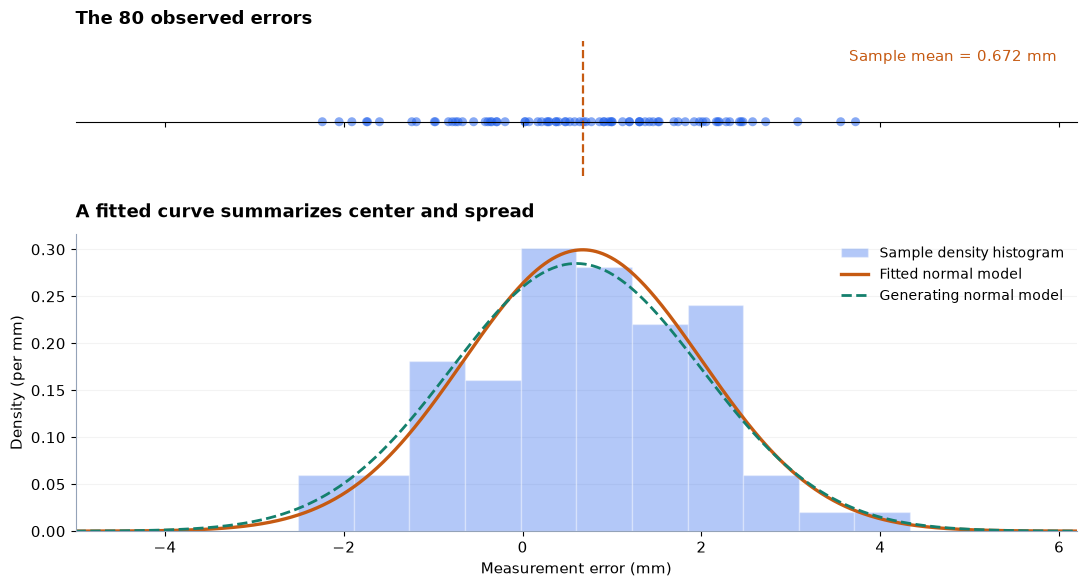

In [2]:
fig, (ax_dots, ax_hist) = plt.subplots(2, 1, figsize=(11, 6), sharex=True,
                                      gridspec_kw={"height_ratios": [1, 2.2]})
ax_dots.scatter(x, np.zeros(sample_n), color=BLUE, s=42, alpha=0.55, edgecolors="none")
ax_dots.axvline(mu_hat, color=ORANGE, linestyle="--", linewidth=1.6)
ax_dots.set_title(f"The {sample_n} observed errors", loc="left", pad=12)
ax_dots.set_yticks([])
ax_dots.set_ylim(-0.4, 0.6)
ax_dots.spines[["left", "right", "top"]].set_visible(False)
ax_dots.spines["bottom"].set_position(("data", 0))
ax_dots.text(0.98, 0.85, f"Sample mean = {mu_hat:.3f} mm", transform=ax_dots.transAxes,
             ha="right", color=ORANGE)

ax_hist.hist(x, bins=np.linspace(plot_lo, plot_hi, 19), density=True,
             color=BLUE, alpha=0.35, edgecolor="white", label="Sample density histogram")
ax_hist.plot(grid, normal_pdf(grid, mu_hat, sigma_hat_mle), color=ORANGE,
             linewidth=2.4, label="Fitted normal model")
ax_hist.plot(grid, normal_pdf(grid, TRUE_MEAN, TRUE_SD), color=TEAL,
             linestyle="--", linewidth=2, label="Generating normal model")
ax_hist.set_title("A fitted curve summarizes center and spread", loc="left", pad=12)
ax_hist.set_ylabel("Density (per mm)")
ax_hist.set_xlabel("Measurement error (mm)")
ax_hist.set_xlim(plot_lo, plot_hi)
ax_hist.legend(frameon=False, fontsize=10)
tidy(ax_hist)
fig.tight_layout(h_pad=1.8)
plt.show()

## 3. Calculate interval probabilities, not curve heights

The normal probability density function is

$$f(x\mid\mu,\sigma)=\frac{1}{\sigma\sqrt{2\pi}}
\exp\left[-\frac{(x-\mu)^2}{2\sigma^2}\right].$$

The height is **density**, measured per millimeter. Probability is area:

$$P(a\le X<b)=\int_a^b f(x)\,dx=F(b)-F(a),$$

where $F(t)=P(X\le t)$ is the cumulative distribution function (CDF).
For a continuous model, including or excluding either endpoint does not change
the probability because $P(X=c)=0$ for every exact value $c$.

We compare an interval near the center, a moderately large positive error,
and a far-tail interval. In the default sample the last interval is empty;
the fitted normal model can still assign positive probability to it.

| Interval (mm) | Observed count | Empirical estimate | Fitted normal estimate | Generating-model probability |
| :--- | ---: | ---: | ---: | ---: |
| [-1, 2) | 57/80 | 71.250% | 73.595% | 71.480% |
| [2, 3) | 12/80 | 15.000% | 11.913% | 11.542% |
| [4, 5) | 0/80 | 0.000% | 0.566% | 0.674% |

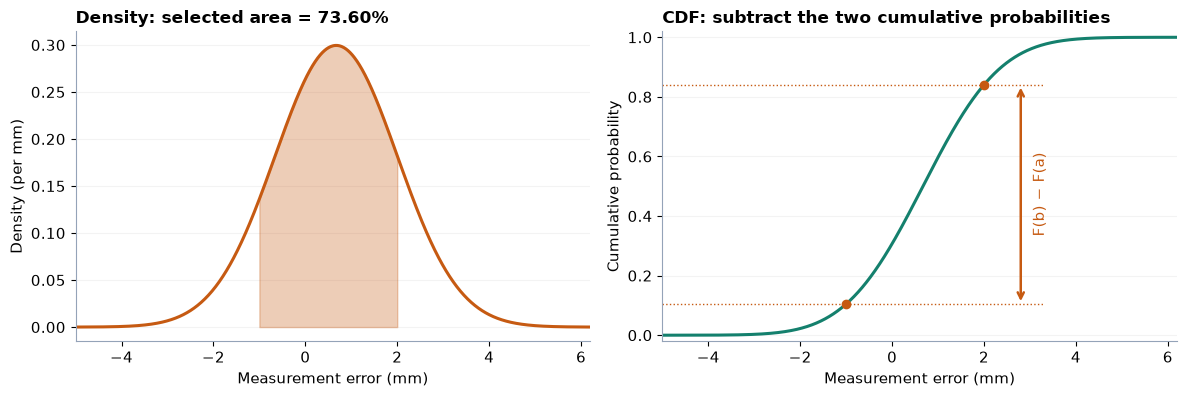

**An exact value and a rounded reading are different events.** Under a continuous normal model, P(X = 1.000… mm) = 0. A display reading of 1.0 mm rounded to the nearest 0.1 mm represents [0.95, 1.05) mm, whose fitted probability is **2.905%**.

In [3]:
intervals = [(-1.0, 2.0), (2.0, 3.0), (4.0, 5.0)]
interval_results = []
rows = ["| Interval (mm) | Observed count | Empirical estimate | Fitted normal estimate | Generating-model probability |",
        "| :--- | ---: | ---: | ---: | ---: |"]
for a, b in intervals:
    count = int(np.count_nonzero((x >= a) & (x < b)))
    empirical = count / sample_n
    fitted = float(normal_probability(a, b, mu_hat, sigma_hat_mle))
    truth = float(normal_probability(a, b, TRUE_MEAN, TRUE_SD))
    interval_results.append((a, b, count, empirical, fitted, truth))
    rows.append(f"| [{a:g}, {b:g}) | {count}/{sample_n} | {empirical:.3%} | {fitted:.3%} | {truth:.3%} |")
display(Markdown("\n".join(rows)))

a, b = intervals[0]
fa = float(normal_cdf(a, mu_hat, sigma_hat_mle))
fb = float(normal_cdf(b, mu_hat, sigma_hat_mle))
shade_grid = np.linspace(a, b, 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.1))
axes[0].plot(grid, normal_pdf(grid, mu_hat, sigma_hat_mle), color=ORANGE, linewidth=2.2)
axes[0].fill_between(shade_grid, normal_pdf(shade_grid, mu_hat, sigma_hat_mle),
                     color=ORANGE, alpha=0.3)
axes[0].set_title(f"Density: selected area = {fb-fa:.2%}", loc="left", fontsize=12)
axes[0].set_ylabel("Density (per mm)")
axes[1].plot(grid, normal_cdf(grid, mu_hat, sigma_hat_mle), color=TEAL, linewidth=2.2)
axes[1].scatter([a,b], [fa,fb], color=ORANGE, zorder=3)
axes[1].hlines([fa,fb], grid[0], b + 1.3, color=ORANGE, linestyle=":", linewidth=1)
axes[1].annotate("", xy=(b+0.8,fb), xytext=(b+0.8,fa),
                 arrowprops={"arrowstyle":"<->", "color":ORANGE, "linewidth":1.8})
axes[1].text(b+1.05, (fa+fb)/2, "F(b) − F(a)", rotation=90, va="center", color=ORANGE)
axes[1].set_title("CDF: subtract the two cumulative probabilities", loc="left", fontsize=12)
axes[1].set_ylabel("Cumulative probability")
axes[1].set_ylim(-0.02, 1.02)
for ax in axes:
    ax.set_xlabel("Measurement error (mm)")
    ax.set_xlim(plot_lo, plot_hi)
    tidy(ax)
fig.tight_layout()
plt.show()

rounded_probability = float(normal_probability(0.95, 1.05, mu_hat, sigma_hat_mle))
display(Markdown(
    "**An exact value and a rounded reading are different events.** Under a continuous "
    "normal model, P(X = 1.000… mm) = 0. A display reading of 1.0 mm rounded to the "
    f"nearest 0.1 mm represents [0.95, 1.05) mm, whose fitted probability is "
    f"**{rounded_probability:.3%}**."
))

## 4. What the normal parameters control

Changing $\mu$ moves the center. Changing $\sigma$ changes the spread and hence
the peak height: a narrower distribution must be taller to keep total area 1.
A density height greater than 1 is allowed; an interval probability still
cannot exceed 1.

For a normal model, the probability within one, two, and three standard
deviations of its mean is about 68.27%, 95.45%, and 99.73%, respectively.
These are properties of the model, not guaranteed percentages in every sample
and not confidence intervals for the unknown mean.

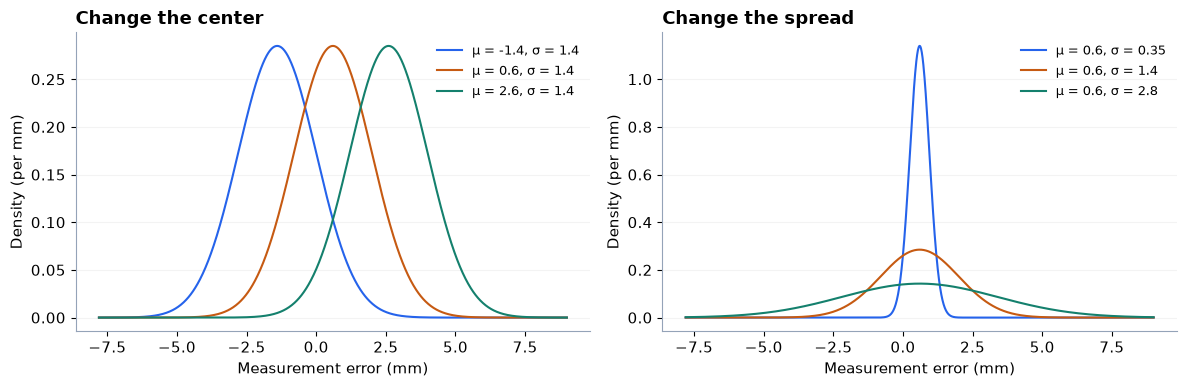

| Normal-model interval | Probability |
| :--- | ---: |
| μ ± 1σ | 68.2689% |
| μ ± 2σ | 95.4500% |
| μ ± 3σ | 99.7300% |

In [4]:
parameter_grid = np.linspace(TRUE_MEAN - 6*TRUE_SD, TRUE_MEAN + 6*TRUE_SD, 1200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for mu, color in zip([TRUE_MEAN-2, TRUE_MEAN, TRUE_MEAN+2], [BLUE,ORANGE,TEAL]):
    axes[0].plot(parameter_grid, normal_pdf(parameter_grid, mu, TRUE_SD),
                 color=color, label=f"μ = {mu:g}, σ = {TRUE_SD:g}")
for sd, color in zip([0.35, 1.4, 2.8], [BLUE,ORANGE,TEAL]):
    axes[1].plot(parameter_grid, normal_pdf(parameter_grid, TRUE_MEAN, sd),
                 color=color, label=f"μ = {TRUE_MEAN:g}, σ = {sd:g}")
axes[0].set_title("Change the center", loc="left")
axes[1].set_title("Change the spread", loc="left")
for ax in axes:
    ax.set_xlabel("Measurement error (mm)")
    ax.set_ylabel("Density (per mm)")
    ax.legend(frameon=False, fontsize=9)
    tidy(ax)
fig.tight_layout()
plt.show()

rows = ["| Normal-model interval | Probability |", "| :--- | ---: |"]
for k in [1,2,3]:
    probability = float(normal_probability(TRUE_MEAN-k*TRUE_SD, TRUE_MEAN+k*TRUE_SD, TRUE_MEAN, TRUE_SD))
    rows.append(f"| μ ± {k}σ | {probability:.4%} |")
display(Markdown("\n".join(rows)))

## 5. When a fitted model can help with limited data

A histogram or empirical count estimates an interval using the observations
inside that interval. A normal model uses all observations to estimate its
center and spread, then uses its assumed shape to calculate the interval area.
When that shape is appropriate, this can improve precision with limited data.
It does not remove uncertainty or guarantee a better answer for every sample.

Repeat the following experiment 2,000 times for each of three sample sizes:
draw a new normal sample, estimate $P(2\le X<3)$ by direct counting, fit a normal
model to that same sample, and estimate the same probability from its CDF.

We report the average estimate and **root mean squared error (RMSE)** against
the known generating-model probability:

$$\mathrm{RMSE}=\sqrt{\frac{1}{R}\sum_{r=1}^R(\hat p_r-p)^2}.$$

RMSE includes both systematic error and variability. The empirical estimate is
unbiased for this fixed interval under independent sampling. The fitted-model
estimate need not be unbiased, even when its RMSE is smaller.

**True interval probability: 11.5417%.**

| Sample size | Mean empirical estimate | Mean model estimate | Empirical RMSE | Model RMSE |
| ---: | ---: | ---: | ---: | ---: |
| 20 | 0.1154 | 0.1100 | 0.0744 | 0.0385 |
| 80 | 0.1156 | 0.1140 | 0.0357 | 0.0184 |
| 400 | 0.1146 | 0.1147 | 0.0161 | 0.0083 |

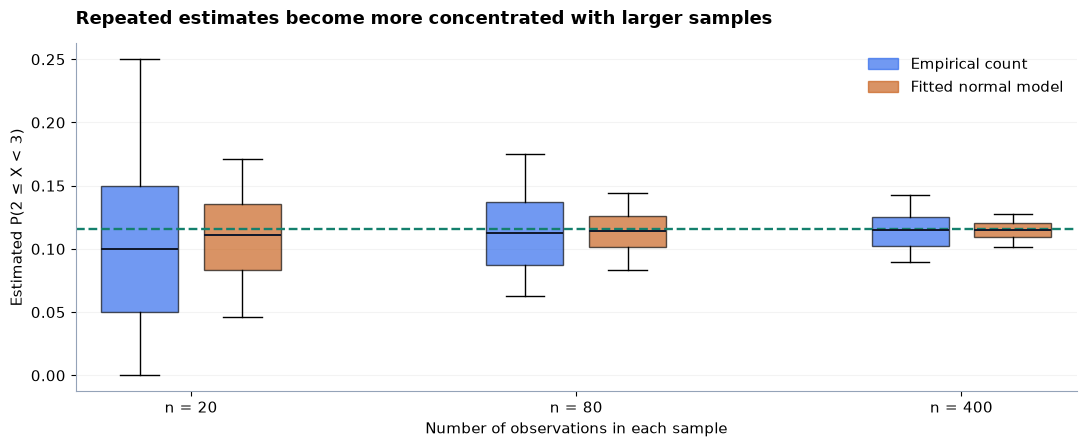

Boxes span the 25th to 75th percentiles of repeated estimates; whiskers span the 5th to 95th percentiles. These are simulation summaries, not confidence intervals for an individual sample. The dashed line is the true probability.

In [5]:
REPETITIONS = 2000
EXPERIMENT_SEED = 20261005
experiment_sizes = [20, 80, 400]
event_a, event_b = 2.0, 3.0
true_event_probability = float(normal_probability(event_a,event_b,TRUE_MEAN,TRUE_SD))
repeated_estimates = {}
experiment_rows = ["| Sample size | Mean empirical estimate | Mean model estimate | Empirical RMSE | Model RMSE |",
                   "| ---: | ---: | ---: | ---: | ---: |"]
for size in experiment_sizes:
    experiment_rng = np.random.default_rng(np.random.SeedSequence([EXPERIMENT_SEED,size]))
    draws = experiment_rng.normal(TRUE_MEAN, TRUE_SD, size=(REPETITIONS,size))
    empirical_estimates = ((draws >= event_a) & (draws < event_b)).mean(axis=1)
    fitted_estimates = normal_probability(event_a,event_b,draws.mean(axis=1),draws.std(axis=1,ddof=0))
    repeated_estimates[size] = {"empirical":empirical_estimates, "fitted":fitted_estimates}
    empirical_rmse = np.sqrt(np.mean((empirical_estimates-true_event_probability)**2))
    fitted_rmse = np.sqrt(np.mean((fitted_estimates-true_event_probability)**2))
    experiment_rows.append(f"| {size} | {empirical_estimates.mean():.4f} | {fitted_estimates.mean():.4f} "
                           f"| {empirical_rmse:.4f} | {fitted_rmse:.4f} |")
display(Markdown(f"**True interval probability: {true_event_probability:.4%}.**\n\n" + "\n".join(experiment_rows)))

fig, ax = plt.subplots(figsize=(11,4.6))
group_centers = []
for i, size in enumerate(experiment_sizes):
    base = 1 + 3*i
    values = repeated_estimates[size]
    boxes = ax.boxplot([values["empirical"],values["fitted"]],
                       positions=[base,base+0.8], widths=0.6,
                       patch_artist=True, showfliers=False, whis=(5,95),
                       medianprops={"color":INK,"linewidth":1.4})
    for patch,color in zip(boxes["boxes"],[BLUE,ORANGE]):
        patch.set_facecolor(color)
        patch.set_alpha(0.65)
    group_centers.append(base+0.4)
ax.axhline(true_event_probability, color=TEAL, linestyle="--", linewidth=1.7)
ax.set_xticks(group_centers, labels=[f"n = {size}" for size in experiment_sizes])
ax.set_xlabel("Number of observations in each sample")
ax.set_ylabel("Estimated P(2 ≤ X < 3)")
ax.set_title("Repeated estimates become more concentrated with larger samples", loc="left", pad=14)
ax.legend(handles=[Patch(color=BLUE,alpha=.65,label="Empirical count"),
                   Patch(color=ORANGE,alpha=.65,label="Fitted normal model")], frameon=False)
tidy(ax)
fig.tight_layout()
plt.show()
display(Markdown("Boxes span the 25th to 75th percentiles of repeated estimates; whiskers span the 5th to 95th percentiles. These are simulation summaries, not confidence intervals for an individual sample. The dashed line is the true probability."))

## 6. Probability and likelihood ask different questions

| Viewpoint | What is fixed? | What varies? | Question |
| :--- | :--- | :--- | :--- |
| Probability | Model parameters | Possible future observations | How often will an event occur? |
| Likelihood | Observed data | Candidate model parameters | Which parameter values better support these observations? |

For independent observations, the joint likelihood is a **product** of
probability masses or densities:

$$L(\theta;x_1,\ldots,x_n)=\prod_{i=1}^{n}f(x_i\mid\theta).$$

Its logarithm is a sum of **log-densities**, not a sum of density heights:

$$\ell(\theta)=\log L(\theta)=\sum_{i=1}^{n}\log f(x_i\mid\theta).$$

For a continuous model, these factors are densities; the likelihood is not the
probability of observing those exact real numbers. Viewed as a function of the
parameters, likelihood is not a probability distribution over those parameters.

For an experiment with the main calibration data, hold $\sigma$ fixed at the
simulation value and vary the candidate mean $\mu$:

$$\ell(\mu)=-n\log(\sigma\sqrt{2\pi})
-\frac{1}{2\sigma^2}\sum_i(x_i-\mu)^2.$$

The maximum occurs at $\hat\mu=\bar x$. When both normal parameters are free,
the MLE variance divides by $n$, as used in section 2. A best-fitting parameter
within a model family does not establish that the family itself is appropriate.

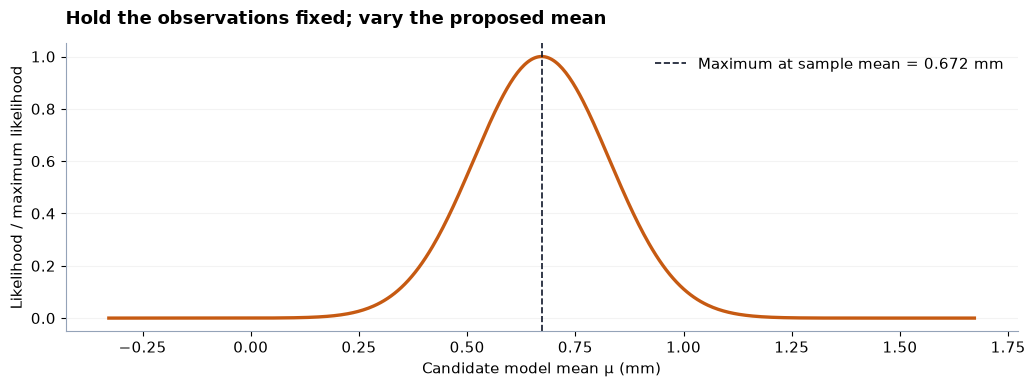

| Candidate mean (mm) | Joint log-likelihood | Likelihood relative to maximum |
| ---: | ---: | ---: |
| 0.1721 | -141.7385 | 0.0061 |
| 0.6721 | -136.6365 | 1.0000 |
| 1.1721 | -141.7385 | 0.0061 |

The peak is scaled to 1 only for display. The curve is not normalized to have area 1 and is **not** a posterior probability density for μ.

In [6]:
fixed_sd = TRUE_SD
def normal_log_likelihood(candidate_mu):
    return float(-sample_n * np.log(fixed_sd*np.sqrt(2*np.pi))
                 - np.sum((x-candidate_mu)**2)/(2*fixed_sd**2))

mean_grid = np.sort(np.unique(np.r_[np.linspace(mu_hat-1.0,mu_hat+1.0,501),mu_hat]))
log_likelihood_values = np.array([normal_log_likelihood(mu) for mu in mean_grid])
max_log_likelihood = normal_log_likelihood(mu_hat)
relative_likelihood = np.exp(log_likelihood_values-max_log_likelihood)

fig, ax = plt.subplots(figsize=(10.5,4))
ax.plot(mean_grid, relative_likelihood, color=ORANGE, linewidth=2.4)
ax.axvline(mu_hat, color=INK, linestyle="--", linewidth=1.2,
           label=f"Maximum at sample mean = {mu_hat:.3f} mm")
ax.set_xlabel("Candidate model mean μ (mm)")
ax.set_ylabel("Likelihood / maximum likelihood")
ax.set_title("Hold the observations fixed; vary the proposed mean", loc="left", pad=14)
ax.legend(frameon=False)
tidy(ax)
fig.tight_layout()
plt.show()

rows = ["| Candidate mean (mm) | Joint log-likelihood | Likelihood relative to maximum |",
        "| ---: | ---: | ---: |"]
for candidate in [mu_hat-0.5,mu_hat,mu_hat+0.5]:
    ll = normal_log_likelihood(candidate)
    rows.append(f"| {candidate:.4f} | {ll:.4f} | {np.exp(ll-max_log_likelihood):.4f} |")
display(Markdown("\n".join(rows)))
display(Markdown("The peak is scaled to 1 only for display. The curve is not normalized to have area 1 and is **not** a posterior probability density for μ."))

## 7. More observations cannot repair the wrong model family

Now consider a device that alternates between two operating modes. In this
separate demonstration, errors cluster near either -2.5 mm or +2.5 mm, with
standard deviation 0.7 mm within each mode. Each mode is selected with probability
one-half. Fitting one normal curve spreads density across the gap between them.

The example uses 1,200 observations. We compare the observed proportion near
zero, a single-normal estimate, and the known two-component generating model.
The mixture-model probability is the weighted sum of the two normal interval
probabilities. It is available here because we know how the data were generated.

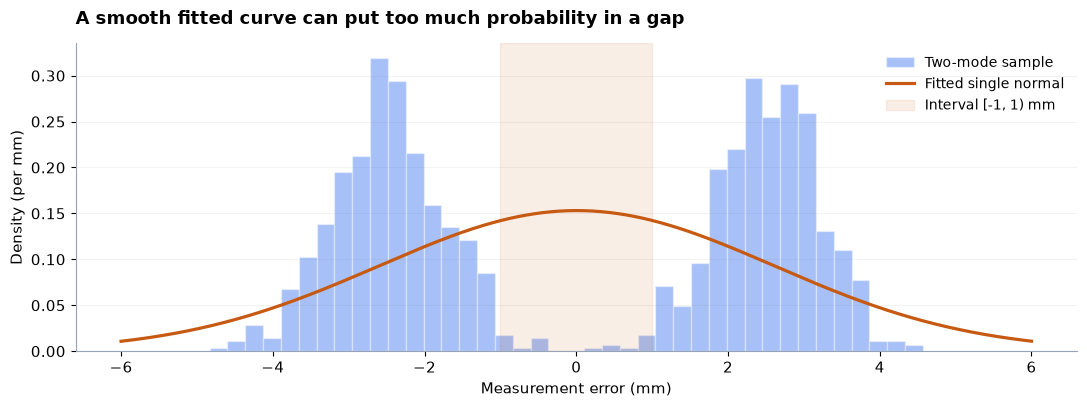

| P(−1 ≤ X < 1) | Value |
| :--- | ---: |
| Observed proportion | 1.333% |
| Fitted single-normal estimate | 29.878% |
| Known two-component model | 1.606% |

In [7]:
mixture_rng = np.random.default_rng(20261006)
mixture_n = 1200
mode_centers = mixture_rng.choice([-2.5,2.5],size=mixture_n)
mixture_data = mode_centers + mixture_rng.normal(0,0.7,size=mixture_n)
wrong_mu = mixture_data.mean()
wrong_sd = mixture_data.std(ddof=0)
mixture_empirical = np.mean((mixture_data >= -1) & (mixture_data < 1))
single_normal_probability = float(normal_probability(-1,1,wrong_mu,wrong_sd))
mixture_true_probability = float(0.5*normal_probability(-1,1,-2.5,0.7)
                                 +0.5*normal_probability(-1,1,2.5,0.7))

mix_grid = np.linspace(-6,6,1000)
fig, ax = plt.subplots(figsize=(11,4.2))
ax.hist(mixture_data,bins=40,density=True,color=BLUE,alpha=.4,edgecolor="white",label="Two-mode sample")
ax.plot(mix_grid,normal_pdf(mix_grid,wrong_mu,wrong_sd),color=ORANGE,linewidth=2.3,label="Fitted single normal")
ax.axvspan(-1,1,color=ORANGE,alpha=.10,label="Interval [-1, 1) mm")
ax.set_xlabel("Measurement error (mm)")
ax.set_ylabel("Density (per mm)")
ax.set_title("A smooth fitted curve can put too much probability in a gap",loc="left",pad=14)
ax.legend(frameon=False,fontsize=10)
tidy(ax)
fig.tight_layout()
plt.show()
display(Markdown(
    "| P(−1 ≤ X < 1) | Value |\n| :--- | ---: |\n"
    f"| Observed proportion | {mixture_empirical:.3%} |\n"
    f"| Fitted single-normal estimate | {single_normal_probability:.3%} |\n"
    f"| Known two-component model | {mixture_true_probability:.3%} |"
))

A model can be precisely fitted and still systematically wrong. Check the
variable's support, distribution shape, independence assumptions, and whether
the process is stable. The value of a model is that it uses a defensible structure
to estimate probabilities; fitting a curve does not establish that structure.

## 8. Binomial: count flagged items in a fixed batch

Suppose an inspection system checks 12 items. Each item independently has a
0.15 probability of being flagged, and that probability is the same for every
item. Let $K$ be the number flagged:

$$K\sim\mathrm{Binomial}(m=12,p=0.15).$$

We use $m$ for the number of trials to distinguish it from the earlier dataset's
sample size. A binomial model requires a fixed trial count, two possible outcomes
per trial, independent trials, and a common event probability $p$.

For exactly $k$ flags,

$$P(K=k)=\binom{m}{k}p^k(1-p)^{m-k},\qquad k=0,1,\ldots,m.$$

One particular order of two flags and ten unflagged items has probability
$p^2(1-p)^{10}$. There are $\binom{12}{2}=66$ ways to choose the two flagged
positions, so the probability of **any** such order is 66 times as large.
The combinatorial factor counts mutually exclusive arrangements; it is not
another per-item probability.

This is a **probability mass function (PMF)**. Unlike a continuous density,
its value at $k=2$ is the probability of exactly two flags. To obtain a range
probability, add the appropriate masses.

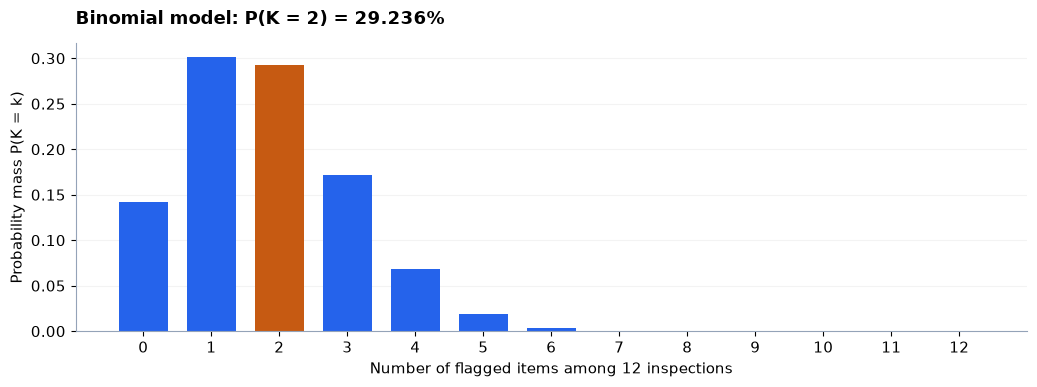

| Calculation | Result |
| :--- | ---: |
| One specified ordering with 2 flags | 0.004430 |
| Number of arrangements | 66 |
| Exactly 2 flags, any ordering | 0.292358 = 29.236% |
| At least 3 flags | 0.264182 = 26.418% |
| Sum over all possible counts | 1.000000 |

In [8]:
trials = 12
flag_probability = 0.15
exact_flags = 2
tail_flags = 3

def binomial_pmf(k, trials, p):
    if trials < 0 or int(trials) != trials or not 0 <= p <= 1:
        raise ValueError("Use an integer trial count >= 0 and 0 <= p <= 1.")
    if k < 0 or k > trials or int(k) != k:
        return 0.0
    return math.comb(int(trials),int(k))*p**k*(1-p)**(trials-k)

flag_k = np.arange(trials+1)
flag_pmf = np.array([binomial_pmf(k,trials,flag_probability) for k in flag_k])
p_exact_flags = float(flag_pmf[exact_flags])
p_tail_flags = float(flag_pmf[flag_k >= tail_flags].sum())
p_one_order = flag_probability**exact_flags * (1-flag_probability)**(trials-exact_flags)

fig, ax = plt.subplots(figsize=(10.5,4))
ax.bar(flag_k,flag_pmf,color=[ORANGE if k==exact_flags else BLUE for k in flag_k],width=.72)
ax.set_xticks(flag_k)
ax.set_xlabel(f"Number of flagged items among {trials} inspections")
ax.set_ylabel("Probability mass P(K = k)")
ax.set_title(f"Binomial model: P(K = {exact_flags}) = {p_exact_flags:.3%}",loc="left",pad=14)
tidy(ax)
fig.tight_layout()
plt.show()

display(Markdown(
    "| Calculation | Result |\n| :--- | ---: |\n"
    f"| One specified ordering with {exact_flags} flags | {p_one_order:.6f} |\n"
    f"| Number of arrangements | {math.comb(trials,exact_flags)} |\n"
    f"| Exactly {exact_flags} flags, any ordering | {p_exact_flags:.6f} = {p_exact_flags:.3%} |\n"
    f"| At least {tail_flags} flags | {p_tail_flags:.6f} = {p_tail_flags:.3%} |\n"
    f"| Sum over all possible counts | {flag_pmf.sum():.6f} |"
))

## 9. One arrival process, two different questions

Suppose calibration jobs arrive according to a **homogeneous Poisson process**
at a constant rate $r=0.4$ jobs per minute. Counts in disjoint time intervals
are independent under this model. A busy period with a different rate or
arrivals in correlated bursts would require a different model.

**Question A: how many jobs arrive in the next 10 minutes?**

The count $K$ follows a Poisson distribution with expected count
$\lambda=rt=0.4\times10=4$:

$$P(K=k)=e^{-\lambda}\frac{\lambda^k}{k!},\qquad k=0,1,2,\ldots.$$

Here $r$ is a **rate per minute**; $\lambda$ is the **expected count within the
chosen window**. Both the mean and variance of a Poisson count equal $\lambda$.

**Question B: how long until the next job arrives?**

The waiting time $W$ is exponential with rate $r$:

$$f(w)=r e^{-rw}\quad(w\ge0),\qquad
P(W\le w)=1-e^{-rw},\qquad E[W]=1/r.$$

The average wait is $1/0.4=2.5$ minutes. The rate is the reciprocal of the
mean waiting time, not the mean waiting time itself. Under this process,
the waiting-time distribution is memoryless:

$$P(W>s+t\mid W>s)=P(W>t).$$

Changing the length of the counting window changes $\lambda=rt$. It does not
change the per-minute rate $r$ or the waiting-time distribution.

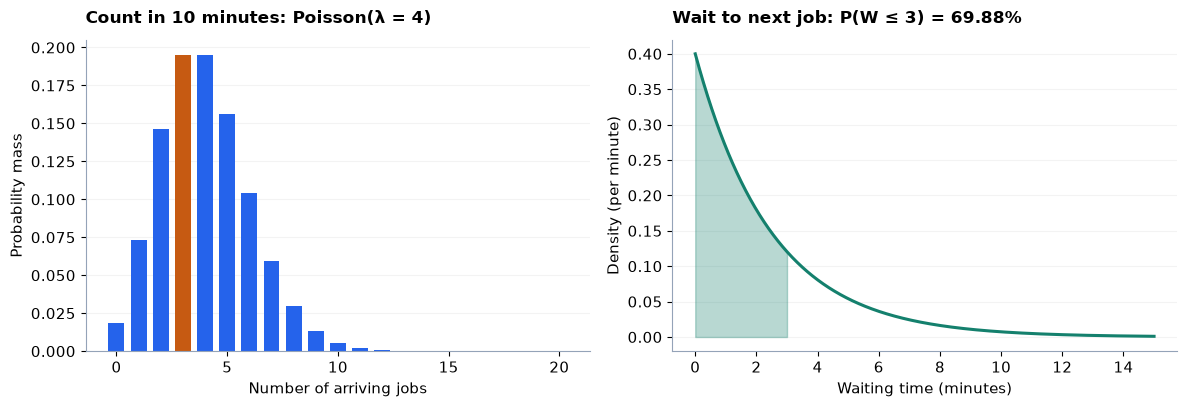

| Question under the arrival model | Probability |
| :--- | ---: |
| Exactly 3 jobs in 10 minutes | 19.5367% |
| At least 5 jobs in 10 minutes | 37.1163% |
| Next job arrives within 3 minutes | 69.8806% |

Poisson probability beyond the displayed count range: 1.92e-09
The Poisson support is unbounded; its plotted bars are not renormalized.
Average waiting time: 2.50 minutes


In [9]:
arrival_rate = 0.4          # jobs per minute
window_minutes = 10.0
expected_arrivals = arrival_rate * window_minutes
exact_arrivals = 3
at_least_arrivals = 5
wait_limit = 3.0           # minutes

def poisson_pmf(k, lam):
    if lam < 0:
        raise ValueError("Poisson mean must be nonnegative.")
    if k < 0 or int(k) != k:
        return 0.0
    if lam == 0:
        return float(k == 0)
    return math.exp(-lam + k*math.log(lam) - math.lgamma(k+1))

arrival_k = np.arange(0, int(np.ceil(expected_arrivals+8*np.sqrt(expected_arrivals)))+1)
arrival_pmf = np.array([poisson_pmf(k,expected_arrivals) for k in arrival_k])
poisson_exact_probability = poisson_pmf(exact_arrivals,expected_arrivals)
poisson_tail_probability = 1-sum(poisson_pmf(k,expected_arrivals) for k in range(at_least_arrivals))
displayed_poisson_mass = float(arrival_pmf.sum())
wait_probability = -math.expm1(-arrival_rate*wait_limit)

time_grid = np.linspace(0,6/arrival_rate,1000)
wait_shade = np.linspace(0,wait_limit,300)
fig, axes = plt.subplots(1,2,figsize=(12,4.2))
axes[0].bar(arrival_k,arrival_pmf,
            color=[ORANGE if k==exact_arrivals else BLUE for k in arrival_k],width=.72)
axes[0].set_title(f"Count in {window_minutes:g} minutes: Poisson(λ = {expected_arrivals:g})",
                  loc="left",fontsize=12,pad=12)
axes[0].set_xlabel("Number of arriving jobs")
axes[0].set_ylabel("Probability mass")
axes[1].plot(time_grid,arrival_rate*np.exp(-arrival_rate*time_grid),color=TEAL,linewidth=2.2)
axes[1].fill_between(wait_shade,arrival_rate*np.exp(-arrival_rate*wait_shade),color=TEAL,alpha=.3)
axes[1].set_title(f"Wait to next job: P(W ≤ {wait_limit:g}) = {wait_probability:.2%}",
                  loc="left",fontsize=12,pad=12)
axes[1].set_xlabel("Waiting time (minutes)")
axes[1].set_ylabel("Density (per minute)")
for ax in axes:
    tidy(ax)
fig.tight_layout()
plt.show()

display(Markdown(
    "| Question under the arrival model | Probability |\n| :--- | ---: |\n"
    f"| Exactly {exact_arrivals} jobs in {window_minutes:g} minutes | {poisson_exact_probability:.4%} |\n"
    f"| At least {at_least_arrivals} jobs in {window_minutes:g} minutes | {poisson_tail_probability:.4%} |\n"
    f"| Next job arrives within {wait_limit:g} minutes | {wait_probability:.4%} |"
))
print(f"Poisson probability beyond the displayed count range: {max(0,1-displayed_poisson_mass):.3g}")
print("The Poisson support is unbounded; its plotted bars are not renormalized.")
print(f"Average waiting time: {1/arrival_rate:.2f} minutes")

## 10. Uniform: equal-length intervals have equal probability

A test scheduler deliberately chooses a continuous random delay between
2 and 7 seconds. The model is $U\sim\mathrm{Uniform}(a=2,b=7)$, with density

$$f(u)=\begin{cases}
1/(b-a),&a\le u\le b,\\
0,&\text{otherwise}.
\end{cases}$$

For an interval $[c,d]$, its probability is the length of its overlap with the
support, divided by the total support length:

$$P(c\le U\le d)=\frac{\max\{0,\min(d,b)-\max(c,a)\}}{b-a}.$$

Thus $P(3\le U\le5)=2/5=0.4$. Any other two-second interval wholly inside
$[2,7]$ has the same probability. Individual exact values still have
probability zero; it is equal-length **intervals** that have equal positive
probability.

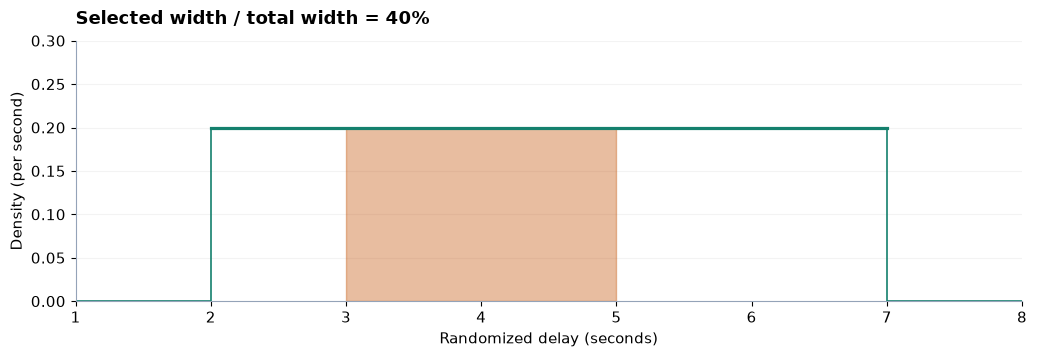

Density height: 0.2 per second
Selected area: 0.2 × 2 = 0.4


In [10]:
uniform_a, uniform_b = 2.0, 7.0
uniform_event_a, uniform_event_b = 3.0, 5.0
uniform_probability = max(0,min(uniform_event_b,uniform_b)-max(uniform_event_a,uniform_a)) / (uniform_b-uniform_a)
uniform_height = 1/(uniform_b-uniform_a)
u_grid = np.linspace(uniform_a,uniform_b,300)
u_shade = np.linspace(max(uniform_a,uniform_event_a),min(uniform_b,uniform_event_b),100)
fig, ax = plt.subplots(figsize=(10.5,3.7))
ax.plot(u_grid,np.full_like(u_grid,uniform_height),color=TEAL,linewidth=2.3)
ax.vlines([uniform_a,uniform_b],0,uniform_height,color=TEAL,linewidth=1.2)
ax.hlines([0,0],[uniform_a-1,uniform_b],[uniform_a,uniform_b+1],color=TEAL,linewidth=1.2)
ax.fill_between(u_shade,uniform_height,color=ORANGE,alpha=.4)
ax.set_xlim(uniform_a-1,uniform_b+1)
ax.set_ylim(0,uniform_height*1.5)
ax.set_xlabel("Randomized delay (seconds)")
ax.set_ylabel("Density (per second)")
ax.set_title(f"Selected width / total width = {uniform_probability:.0%}",loc="left",pad=12)
tidy(ax)
fig.tight_layout()
plt.show()
print(f"Density height: {uniform_height:g} per second")
print(f"Selected area: {uniform_height:g} × {uniform_event_b-uniform_event_a:g} = {uniform_probability:g}")

## 11. A compact reference

| Model | Possible values | Parameters | Mean | Variance | How to get a probability |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Binomial | Integers $0,\ldots,m$ | Trial count $m$, probability $p$ | $mp$ | $mp(1-p)$ | Add PMF values for the selected counts. |
| Poisson | Integers $0,1,2,\ldots$ | Expected count $\lambda=rt$ | $\lambda$ | $\lambda$ | Add PMF values or use a complement. |
| Normal | All real values | Mean $\mu$, SD $\sigma>0$ | $\mu$ | $\sigma^2$ | Subtract CDF values: $F(b)-F(a)$. |
| Exponential | Nonnegative values | Rate $r>0$ | $1/r$ | $1/r^2$ | For $0\le a<b$, use $e^{-ra}-e^{-rb}$. |
| Uniform | A bounded interval $[a,b]$ | Bounds $a<b$ | $(a+b)/2$ | $(b-a)^2/12$ | Divide overlap length by support length. |

**Probability mass, density, and likelihood:** a PMF gives probabilities at
discrete outcomes; a PDF gives densities, whose areas are probabilities;
a likelihood holds the data fixed and compares candidate parameters. For
independent data, multiply masses/densities or add their logarithms.

**What makes a model useful:** a suitable family can estimate probabilities
using fewer parameters than a collection of independent bin counts. The
benefit depends on the assumptions being appropriate. More independent,
representative observations generally improve precision, but neither sample
size nor a smooth curve guarantees correct future predictions if the process
changes or the model is unsuitable.

## 12. Experiments to try

1. Change `sample_n` from 80 to 25 or 500 and run all cells. Compare the empirical,
   fitted-model, and generating-model interval probabilities. Does the far-tail
   interval remain empty in every sample?
2. Change `REPETITIONS` from 2,000 to 500 or 5,000 in section 5. This changes how
   precisely the simulation describes repeated estimates; it does not change
   the number of observations inside each of those samples.
3. Change `flag_probability` from 0.15 to 0.35. Predict how the binomial PMF and
   the probability of at least three flags will change.
4. Double `window_minutes` while keeping `arrival_rate` fixed. The expected
   Poisson count doubles; the exponential waiting-time curve stays the same.
5. Widen the uniform support while keeping the selected interval inside it.
   Predict how its density height and selected probability change.
6. In the two-mode example, explain why collecting still more observations
   would not make a single normal curve recover the central gap.

Controls and output tables update when rerun. Written worked examples describe
the default values. Parameter changes must still respect each model's support
and assumptions.

**Connections:** the distinction between a population parameter and its estimate
is developed in `population_vs_sample_statistics.ipynb`; observed proportions,
bin widths, and histogram areas are developed in `histogram.ipynb`.